# New version with LSTM fixed
## DNA free-energy prediction · held-out performance and uncertainty

We revisit the DNA-strand regression experiment using the corrected LSTM trained locally on the original NUPACK-generated dataset. This notebook recomputes metrics, uncertainty intervals, a paired predictive-skill test and figures from saved predictions. **It does not retrain the network when run.** The original notebooks remain unchanged.

The comparison focuses on the corrected LSTM and the saved larger Transformer. Each model is evaluated on its own available cohort, followed by a paired analysis on uniquely identified common strands.

In [1]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / 'corrected_lstm').exists():
    ROOT = ROOT.parent
ART = ROOT / 'corrected_lstm'
FIG = ROOT / 'doc' / 'images'
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'figure.facecolor': 'white',
                     'axes.facecolor': 'white', 'savefig.facecolor': 'white'})
BLUE, TEAL, ORANGE, GRAY = '#245B8A', '#218C84', '#C67A35', '#66717D'
ref = json.loads((ART / 'reference.json').read_text())
saved = json.loads((ART / 'final_results.json').read_text())
history = pd.read_json(ART / 'history.json')
plan = json.loads((ART / 'inference_plan.json').read_text())
display(Markdown('**Inference plan:** ' + plan['status']))

**Inference plan:** Retrospective exploratory; outcomes were already known before inference choices.

## 1. Data, split and the strand-mixing bug

The dataset contains one million distinct, randomly generated 30-base DNA sequences with simulated free-energy labels. The corrected run used **800,000 training, 100,000 validation and 100,000 test strands**, with seed 20261025. The original dataset was checked for valid bases, finite labels, fixed lengths and duplicates before training. Exact split indices and a dataset checksum are retained.

The old notebook flattened each strand into 120 one-hot values. An input of shape `[batch, 120]` is interpreted by PyTorch's LSTM as an **unbatched sequence**: unrelated strands become recurrent time steps. State was reset between calls, but flowed between strands inside a batch.

The corrected input is `[batch, 30, 4]`, with `batch_first=True`. Recurrence proceeds over bases within each independent strand. The final hidden state predicts one free energy per strand.

```python
self.lstm = nn.LSTM(4, 64, 2, dropout=0.6, batch_first=True)
self.fc = nn.Linear(64, 1)

def forward(self, x):
    _, (h, _) = self.lstm(x)
    return self.fc(h[-1]).squeeze(-1)
```

The complete implementation is in `corrected_lstm/train_corrected.py`. Original weights cannot be resumed after changing input dimensions. This was fresh CPU training with **64 hidden units rather than the original 270**, so its improvement cannot be attributed solely to the axis correction.

In [2]:
predictions = np.load(ART / 'test_predictions.npz')
y = predictions['target'].astype(np.float64)
pred = predictions['prediction'].astype(np.float64)
row = predictions['original_row']
split = np.load(ART / 'split_indices.npz')
assert np.array_equal(row, split['test'])
all_rows = np.concatenate([split[k] for k in ['train', 'validation', 'test']])
assert len(np.unique(all_rows)) == len(all_rows) == 1_000_000
assert len(y) == 100_000 and np.isfinite(y).all() and np.isfinite(pred).all()
checks = json.loads((ART / 'verification.json').read_text())
assert all(checks['checks'].values())
assert checks['absolute_difference'] < 1e-6
data_path = ROOT / 'src' / 'data' / 'strandenergylist.json'
if data_path.exists():
    assert hashlib.sha256(data_path.read_bytes()).hexdigest() == ref['data_sha256']
print('100,000 finite predictions; disjoint splits; saved checkpoint checks passed.')
print('Dataset SHA-256:', ref['data_sha256'])
print('Rebatched checkpoint MSE difference:', checks['absolute_difference'])

100,000 finite predictions; disjoint splits; saved checkpoint checks passed.
Dataset SHA-256: fac07d8c27b7b39dc8233e92ddb161710b082e433894cc8cb2ddafafbb30435c
Rebatched checkpoint MSE difference: 7.251876876779306e-11


## 2. Training and checkpoint selection

Two LSTM layers and a linear output give 51,265 parameters. Training used Adam (learning rate 0.001), batches of 512, dropout 0.6 between layers, and a gradient-norm cap of 5. Training was limited to 15 epochs, with patience 4. The checkpoint with minimum validation MSE was selected before the test set was evaluated.

The test result was already known when this statistical analysis was designed. The inference below is therefore **retrospective and exploratory**. No new model or hyperparameter search was conducted. The earlier dataset and models are retained unchanged.

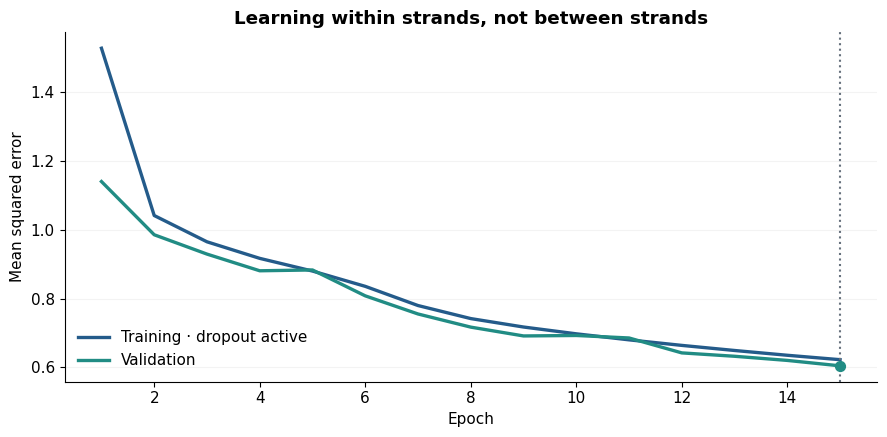

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(history.epoch, history.training_mse, color=BLUE, lw=2.4, label='Training · dropout active')
ax.plot(history.epoch, history.validation_mse, color=TEAL, lw=2.4, label='Validation')
ax.axvline(saved['selected_epoch'], color=GRAY, ls=':', lw=1.5)
ax.scatter([saved['selected_epoch']], [saved['validation_mse']], color=TEAL, s=50, zorder=3)
ax.set(xlabel='Epoch', ylabel='Mean squared error', title='Learning within strands, not between strands')
ax.legend(frameon=False); ax.grid(axis='y', alpha=0.14)
fig.tight_layout(); fig.savefig(FIG / 'lstm_fixed_learning.png', dpi=190, bbox_inches='tight')
plt.show()

## 3. Held-out regression metrics

For target $y_i$ and fixed prediction $\hat y_i$,

$$\mathrm{MSE}=\frac1n\sum_i(y_i-\hat y_i)^2,
\qquad R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y_{\mathrm{test}})^2}.$$

Held-out $R^2$ measures the fraction of the test set's centered sum of squares removed by the predictions. It can be negative. It is **not** squared correlation, which can look favorable even when predictions are biased or miscalibrated. The test mean is used only to define the $R^2$ denominator, not to fit the model or a deployable benchmark.

For the predictive-skill test, the benchmark is the constant mean **estimated on training labels**, retained in `reference.json`.

In [4]:
residual = pred - y
model_loss = residual**2
baseline_loss = (y - ref['training_mean'])**2
gain = baseline_loss - model_loss
n = len(y)
mse = model_loss.mean()
sst_per_observation = np.mean((y - y.mean())**2)
r2 = 1 - mse / sst_per_observation
metrics = pd.Series({'MSE': mse, 'RMSE': np.sqrt(mse), 'MAE': np.abs(residual).mean(),
                     'Test R²': r2, 'Bias (prediction − label)': residual.mean(),
                     'Training-mean benchmark MSE': baseline_loss.mean(),
                     'Mean squared-loss improvement': gain.mean()})
assert abs(mse - saved['test_mse']) < 1e-6
assert abs(baseline_loss.mean() - saved['training_mean_test_mse']) < 1e-10
display(metrics.to_frame('Estimate').style.format('{:.6f}'))

,Estimate
MSE,0.599550
RMSE,0.774306
MAE,0.572293
Test R²,0.630877
Bias (prediction − label),-0.020680
Training-mean benchmark MSE,1.624360
Mean squared-loss improvement,1.024810


## 4. Paired bootstrap and one primary hypothesis test

Resample **whole `(label, prediction)` pairs**, not labels and predictions independently. Each resample recomputes $R^2$, including its centered denominator, MSE, bias and the mean loss improvement. We use 2,000 resamples and seed 751903, fixed in the analysis plan before running these calculations.

The primary hypothesis concerns $d_i=(y_i-\bar y_{\mathrm{train}})^2-(y_i-\hat y_i)^2$:

$$H_0:E[d_i]\leq0,\qquad H_1:E[d_i]>0.$$

The observed statistic is $T=\bar d/(s_d/\sqrt n)$. A studentized bootstrap imposes the boundary null by centering each resampled mean:

$$T_b^*=\frac{\bar d_b^*-\bar d}{s_{d,b}^*/\sqrt n}.$$

The reported upper-tail Monte Carlo p-value is $(1+\#\{T_b^*\geq T\})/(B+1)$. It is a finite-resolution bootstrap approximation, not an exact permutation test. We do not claim an arbitrarily tiny p-value when there are no exceedances.

Percentile 95% confidence intervals describe effect-size uncertainty. A mean-improvement interval above zero supports predictive skill against this fixed mean benchmark. This is one primary hypothesis; the other intervals below are estimation summaries, not additional superiority tests.

**Assumptions:** test strands are independent draws from the simulated sequence-generating distribution and losses have finite variance. Resampling is conditional on this fitted model and split. It does not cover training-seed variability, model selection across repeated experiments, new sequence populations, or experimental thermodynamic error. Normal residuals are not required for this large-sample bootstrap procedure.

In [5]:
B, SEED = 2000, 751903
rng = np.random.default_rng(SEED)
boot = np.empty((B, 5))  # R2, MSE, mean gain, mean residual, null t
gain_mean = gain.mean()
gain_se = gain.std(ddof=1) / np.sqrt(n)
observed_t = gain_mean / gain_se
for start in range(0, B, 20):
    stop = min(start + 20, B)
    idx = rng.integers(0, n, size=(stop - start, n))
    yy, ll, dd, rr = y[idx], model_loss[idx], gain[idx], residual[idx]
    boot[start:stop, 0] = 1 - ll.mean(axis=1) / yy.var(axis=1)
    boot[start:stop, 1] = ll.mean(axis=1)
    boot[start:stop, 2] = dd.mean(axis=1)
    boot[start:stop, 3] = rr.mean(axis=1)
    boot[start:stop, 4] = ((dd.mean(axis=1) - gain_mean)
                            / (dd.std(axis=1, ddof=1) / np.sqrt(n)))
ci = np.quantile(boot[:, :4], [0.025, 0.975], axis=0)
exceedances = int(np.sum(boot[:, 4] >= observed_t))
p_boot = (1 + exceedances) / (B + 1)
# Monte Carlo uncertainty in the bootstrap tail probability (Clopper–Pearson).
mc_tail_upper = (1.0 if exceedances == B else
                 float(stats.beta.ppf(0.95, exceedances + 1, B - exceedances)))
inference = pd.DataFrame({'Estimate': [r2, mse, gain_mean, residual.mean()],
                          '95% lower': ci[0], '95% upper': ci[1]},
                         index=['Test R²', 'MSE', 'Mean squared-loss improvement', 'Bias'])
display(inference.style.format('{:.6f}'))
print(f'Primary studentized statistic: {observed_t:.3f}')
print(f'Null-bootstrap exceedances: {exceedances}/{B}')
print(f'One-sided bootstrap Monte Carlo p-value: {p_boot:.6f}')
print(f'95% Monte Carlo upper bound on bootstrap tail probability: {mc_tail_upper:.6f}')
print('This Monte Carlo bound does not measure bootstrap approximation error.')
np.savez_compressed(ART / 'bootstrap_replicates.npz', statistics=boot)

Primary studentized statistic: 123.743
Null-bootstrap exceedances: 0/2000
One-sided bootstrap Monte Carlo p-value: 0.000500
95% Monte Carlo upper bound on bootstrap tail probability: 0.001497
This Monte Carlo bound does not measure bootstrap approximation error.


,Estimate,95% lower,95% upper
Test R²,0.630877,0.626336,0.635508
MSE,0.599550,0.591185,0.608056
Mean squared-loss improvement,1.024810,1.008701,1.041306
Bias,-0.020680,-0.025410,-0.015911


## 5. Where do errors occur?

The prediction plot uses all test strands; the diagonal represents perfect prediction. The residual plot checks bias across the predicted-energy range using decile groups. Error bars are pointwise normal-approximation 95% intervals for each group's mean residual, conditional on those groups. They are diagnostic, not simultaneous confidence bands or separate hypothesis tests.

We also summarize MSE within four equally sized groups defined by true test energy. These are descriptive error summaries, not claims about architecture superiority. Equal-count groups avoid confusing a small overall MSE with uniformly good performance across the energy distribution.

,n,MSE
energy_group,,
Lowest energy,25000,1.394435
Q2,25000,0.393792
Q3,25000,0.306622
Highest energy,25000,0.303350


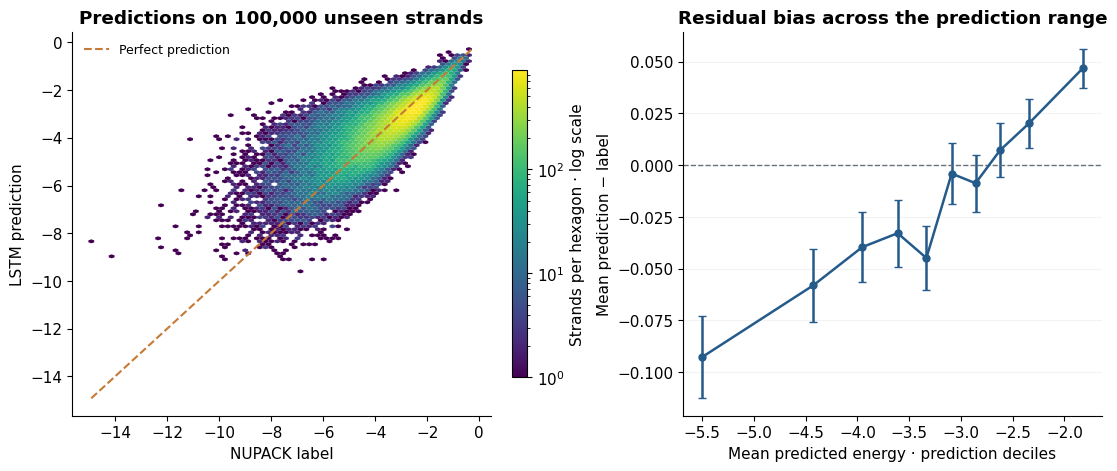

In [6]:
groups = pd.qcut(pred, 10, labels=False, duplicates='drop')
cal = pd.DataFrame({'prediction': pred, 'residual': residual, 'group': groups}).groupby('group').agg(
    prediction=('prediction', 'mean'), bias=('residual', 'mean'),
    sd=('residual', 'std'), count=('residual', 'size'))
cal['half_width'] = 1.96 * cal.sd / np.sqrt(cal['count'])
quartile = pd.qcut(y, 4, labels=['Lowest energy', 'Q2', 'Q3', 'Highest energy'])
quartiles = pd.DataFrame({'energy_group': quartile, 'squared_error': model_loss}).groupby(
    'energy_group', observed=True).agg(n=('squared_error', 'size'), MSE=('squared_error', 'mean'))
display(quartiles.style.format({'MSE': '{:.6f}'}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), constrained_layout=True)
hb = axes[0].hexbin(y, pred, gridsize=65, mincnt=1, bins='log', cmap='viridis', linewidths=0,
                    rasterized=True)
limits = [min(y.min(), pred.min()), max(y.max(), pred.max())]
axes[0].plot(limits, limits, '--', color=ORANGE, lw=1.5, label='Perfect prediction')
axes[0].set(xlabel='NUPACK label', ylabel='LSTM prediction', title='Predictions on 100,000 unseen strands')
axes[0].legend(frameon=False, fontsize=9)
fig.colorbar(hb, ax=axes[0], label='Strands per hexagon · log scale', shrink=0.8)
axes[1].errorbar(cal.prediction, cal.bias, yerr=cal.half_width, fmt='o-', color=BLUE,
                 capsize=3, lw=1.8, ms=5)
axes[1].axhline(0, color=GRAY, ls='--', lw=1)
axes[1].set(xlabel='Mean predicted energy · prediction deciles', ylabel='Mean prediction − label',
             title='Residual bias across the prediction range')
axes[1].grid(axis='y', alpha=0.14)
fig.savefig(FIG / 'lstm_fixed_predictions.png', dpi=190, bbox_inches='tight')
plt.show()

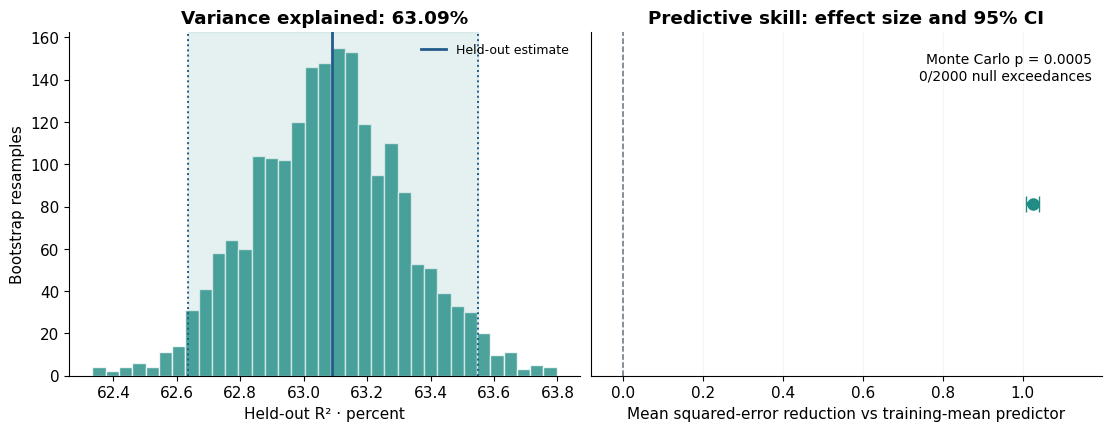

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
axes[0].hist(100 * boot[:, 0], bins=35, color=TEAL, alpha=0.8, edgecolor='white')
axes[0].axvspan(100 * ci[0, 0], 100 * ci[1, 0], color=TEAL, alpha=0.12)
axes[0].axvline(100 * r2, color=BLUE, lw=2, label='Held-out estimate')
for end in ci[:, 0]: axes[0].axvline(100 * end, color=BLUE, ls=':', lw=1.4)
axes[0].set(xlabel='Held-out R² · percent', ylabel='Bootstrap resamples',
             title=f'Variance explained: {100*r2:.2f}%')
axes[0].legend(frameon=False, fontsize=9)
axes[1].errorbar([gain_mean], [0], xerr=[[gain_mean-ci[0, 2]], [ci[1, 2]-gain_mean]],
                 fmt='o', color=TEAL, ms=8, capsize=6, lw=3)
axes[1].axvline(0, color=GRAY, ls='--', lw=1.1)
axes[1].set(xlabel='Mean squared-error reduction vs training-mean predictor',
             title='Predictive skill: effect size and 95% CI', yticks=[], ylim=(-0.6, 0.6))
axes[1].set_xlim(-0.08, ci[1, 2]*1.15)
axes[1].text(0.98, 0.94, f'Monte Carlo p = {p_boot:.4f}\n{exceedances}/{B} null exceedances',
              transform=axes[1].transAxes, ha='right', va='top', fontsize=10)
axes[1].grid(axis='x', alpha=0.12)
fig.savefig(FIG / 'lstm_fixed_inference.png', dpi=190, bbox_inches='tight')
plt.show()

## 6. Recovering the larger Transformer's evaluation

The original `src/data.csv` contains 100,000 prediction–label pairs produced by `src/results/AptAnalysis.ipynb`. They correspond to the **saved larger-Transformer checkpoint**, whose MSE is about 0.1564, not its best reported 0.12. The evaluation data were monitored historically; inference cannot undo that selection or make them an independent final test.

We verify the labels against the original dataset at the original training dtype (float32), including multiplicities. Given the documented 900,000/100,000 split, its training-label mean can be recovered by subtracting the sum of evaluation labels from the sum of all labels. This reconstructs the mean benchmark, not unavailable split indices or a new model.

For a genuine paired model comparison we require common strands. A label is used as an identifier **only when its canonical float32 value occurs exactly once in the entire original dataset and once in the CSV**. Ambiguous matches are excluded. This is reconstructed identification, not an archived sequence ID. The matched labels must agree exactly with the corrected LSTM's saved test rows. The resulting subset is not necessarily representative of the full energy distribution.

The extension uses the same bootstrap procedure. Seeds 751904 and 751905 and a three-comparison Holm family were recorded before running the extension. The original LSTM inference was already known; all testing remains retrospective and exploratory.

In [8]:
raw_rows = json.loads(data_path.read_text())
all_y = np.asarray([r[1] for r in raw_rows], dtype=np.float32)
del raw_rows
historical = pd.read_csv(ROOT / 'src' / 'data.csv', float_precision='round_trip')
assert historical.shape == (100_000, 2)
assert historical.columns.tolist() == ['true', 'predict']
tx_y32 = historical['true'].to_numpy(dtype=np.float32)
tx_y = tx_y32.astype(np.float64)
tx_pred = historical['predict'].to_numpy(dtype=np.float64)
assert np.isfinite(tx_pred).all()
assert np.allclose(tx_y, historical['true'].to_numpy(), rtol=0, atol=2e-14)
values, first_row, counts = np.unique(all_y, return_index=True, return_counts=True)
csv_values, csv_counts = np.unique(tx_y32, return_counts=True)
positions = np.searchsorted(values, csv_values)
assert np.all(positions < len(values))
assert np.array_equal(values[positions], csv_values)
assert np.all(csv_counts <= counts[positions])
tx_training_mean = (all_y.astype(float).sum() - tx_y.sum()) / 900_000

pos = np.searchsorted(values, tx_y32)
unique = ((counts[pos] == 1)
          & (csv_counts[np.searchsorted(csv_values, tx_y32)] == 1))
candidate_row = first_row[pos[unique]]
common_row, tx_candidate_ix, lstm_ix = np.intersect1d(
    candidate_row, row, return_indices=True)
tx_ix = np.flatnonzero(unique)[tx_candidate_ix]
assert np.array_equal(all_y[common_row], tx_y32[tx_ix])
assert np.array_equal(y[lstm_ix], tx_y[tx_ix])
assert len(common_row) == 9371
np.savez_compressed(ART / 'matched_predictions.npz', original_row=common_row,
                    target=y[lstm_ix], lstm=pred[lstm_ix], transformer=tx_pred[tx_ix])
matching = {'historical_csv_rows': len(tx_y), 'unique_identifiable_rows': int(unique.sum()),
            'ambiguous_rows_excluded': int((~unique).sum()), 'common_strands': len(common_row),
            'identification': 'Unique canonical float32 target values; not original archived IDs',
            'recovered_transformer_training_mean': float(tx_training_mean),
            'historical_csv_sha256': hashlib.sha256((ROOT/'src'/'data.csv').read_bytes()).hexdigest(),
            'evaluation_status': 'Historically monitored evaluation set; retrospective inference'}
(ART / 'matching_audit.json').write_text(json.dumps(matching, indent=2))
display(pd.Series(matching).to_frame('Audit'))

,Audit
historical_csv_rows,100000
unique_identifiable_rows,93788
ambiguous_rows_excluded,6212
common_strands,9371
identification,Unique canonical float32 target values; not or...
recovered_transformer_training_mean,-3.345366
historical_csv_sha256,f61b1a916021f22990aa137fcfc47c7950138cc408936f...
evaluation_status,Historically monitored evaluation set; retrosp...


In [9]:
def paired_loss_bootstrap(target, reference_loss, model_loss, seed):
    """Whole-strand paired resampling; model A minus B loss favors B when positive."""
    target = np.asarray(target, dtype=float)
    reference_loss = np.asarray(reference_loss, dtype=float)
    model_loss = np.asarray(model_loss, dtype=float)
    diff = reference_loss - model_loss
    size = len(diff)
    estimate = diff.mean()
    se = diff.std(ddof=1) / np.sqrt(size)
    statistic = estimate / se
    rng = np.random.default_rng(seed)
    out = np.empty((B, 5))  # model R2, model MSE, loss gain, null t, reference MSE
    for start in range(0, B, 20):
        stop = min(start+20, B)
        idx = rng.integers(0, size, size=(stop-start, size))
        dd, ll, aa = diff[idx], model_loss[idx], reference_loss[idx]
        out[start:stop,0] = 1-ll.mean(axis=1)/target[idx].var(axis=1)
        out[start:stop,1] = ll.mean(axis=1)
        out[start:stop,2] = dd.mean(axis=1)
        out[start:stop,3] = ((dd.mean(axis=1)-estimate)
                            /(dd.std(axis=1,ddof=1)/np.sqrt(size)))
        out[start:stop,4] = aa.mean(axis=1)
    count = int((out[:,3] >= statistic).sum())
    return {'n': size, 'mse': float(model_loss.mean()),
            'r2': float(1-model_loss.mean()/target.var()),
            'gain': float(estimate), 'gain_se': float(se), 'statistic': float(statistic),
            'mse_ci95': np.quantile(out[:,1],[.025,.975]).tolist(),
            'r2_ci95': np.quantile(out[:,0],[.025,.975]).tolist(),
            'gain_ci95': np.quantile(out[:,2],[.025,.975]).tolist(),
            'reference_mse_ci95': np.quantile(out[:,4],[.025,.975]).tolist(),
            'p_raw': (count+1)/(B+1), 'null_exceedances': count}, out

tx_loss = (tx_pred-tx_y)**2
tx_baseline_loss = (tx_y-tx_training_mean)**2
tx_result, tx_boot = paired_loss_bootstrap(tx_y, tx_baseline_loss, tx_loss, 751904)
assert abs(tx_result['mse']-0.15640475240276502) < 1e-12
common_y = y[lstm_ix]
common_lstm_loss = (pred[lstm_ix]-common_y)**2
common_tx_loss = (tx_pred[tx_ix]-common_y)**2
matched_result, matched_boot = paired_loss_bootstrap(
    common_y, common_lstm_loss, common_tx_loss, 751905)
np.savez_compressed(ART/'additional_bootstrap_replicates.npz',
                    transformer=tx_boot, matched=matched_boot)

### Results and multiplicity

There are three exploratory superiority comparisons: corrected LSTM versus its training-mean benchmark; historical larger Transformer versus its recovered training-mean benchmark; and larger Transformer versus corrected LSTM on the matched cohort. A positive mean loss reduction favors the model named first in the table. Raw and Holm-adjusted p-values are reported together. The family contains the three stated comparisons between the two models and their constant benchmarks.

The intervals are pointwise 95% estimates. Holm controls the rejection family under valid component p-values; here those component tests are bootstrap approximations conditional on the fitted models and the described cohorts. It does not correct historical checkpoint selection, the retrospective choice of analysis, or uncertainty over training seeds.

In [10]:
raw_p = np.array([p_boot, tx_result['p_raw'], matched_result['p_raw']])
order = np.argsort(raw_p, kind='stable')
adjusted = np.empty(3)
adjusted[order] = np.minimum(1, np.maximum.accumulate((3-np.arange(3))*raw_p[order]))
tests = pd.DataFrame({
    'Comparison': ['Corrected LSTM vs training mean', 'Larger Transformer vs training mean',
                   'Larger Transformer vs corrected LSTM · matched'],
    'n': [n, tx_result['n'], matched_result['n']],
    'Mean loss reduction': [gain_mean, tx_result['gain'], matched_result['gain']],
    '95% lower': [ci[0,2],tx_result['gain_ci95'][0],matched_result['gain_ci95'][0]],
    '95% upper': [ci[1,2],tx_result['gain_ci95'][1],matched_result['gain_ci95'][1]],
    'Studentized statistic': [observed_t,tx_result['statistic'],matched_result['statistic']],
    'Raw Monte Carlo p': raw_p, 'Holm p': adjusted,
    'Null exceedances': [exceedances,tx_result['null_exceedances'],matched_result['null_exceedances']]})
tests.to_csv(ART/'model_statistical_tests.csv',index=False)
display(tests.style.format({'Mean loss reduction':'{:.5f}','95% lower':'{:.5f}',
                            '95% upper':'{:.5f}','Studentized statistic':'{:.2f}',
                            'Raw Monte Carlo p':'{:.6f}','Holm p':'{:.6f}'}).hide(axis='index'))
model_results = {'larger_transformer': tx_result, 'matched_comparison': matched_result,
                 'matched_lstm_mse': float(common_lstm_loss.mean()),
                 'matched_lstm_r2': float(1-common_lstm_loss.mean()/common_y.var()),
                 'holm_pvalues': adjusted.tolist(), 'bootstrap_replicates': B,
                 'status': 'Retrospective conditional inference; historical checkpoint selection unadjusted'}
(ART/'other_model_results.json').write_text(json.dumps(model_results,indent=2))
print('95% R² interval for saved larger Transformer:', tx_result['r2_ci95'])
print('A Monte Carlo p near 0.0005 is the resolution floor for 2,000 resamples.')

95% R² interval for saved larger Transformer: [0.9037906999136932, 0.9064131392549163]
A Monte Carlo p near 0.0005 is the resolution floor for 2,000 resamples.


Comparison,n,Mean loss reduction,95% lower,95% upper,Studentized statistic,Raw Monte Carlo p,Holm p,Null exceedances
Corrected LSTM vs training mean,100000,1.02481,1.00870,1.04131,123.74,0.000500,0.001499,0
Larger Transformer vs training mean,100000,1.49167,1.47247,1.51064,147.66,0.000500,0.001499,0
Larger Transformer vs corrected LSTM · matched,9371,0.44503,0.41721,0.47309,31.28,0.000500,0.001499,0


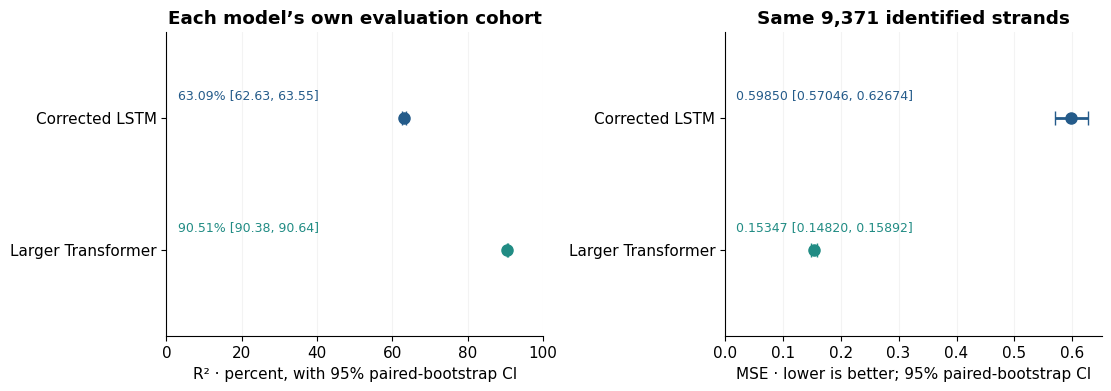

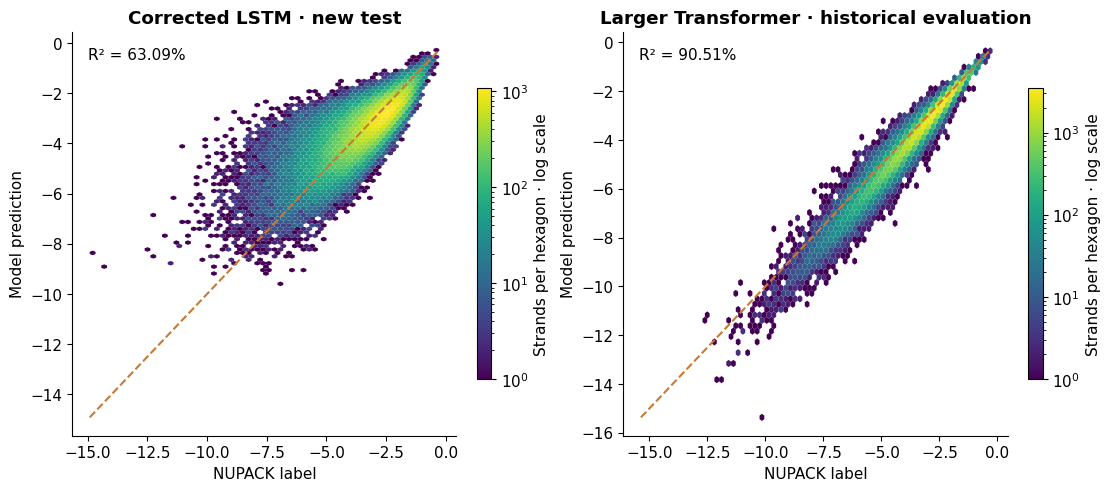

In [11]:
fig, axes = plt.subplots(1,2,figsize=(11,3.8),constrained_layout=True)
for i,(name,estimate,bounds,color) in enumerate([
    ('Corrected LSTM · new test',r2,ci[:,0],BLUE),
    ('Larger Transformer · historical evaluation',tx_result['r2'],tx_result['r2_ci95'],TEAL)]):
    axes[0].errorbar([100*estimate],[1-i],xerr=[[100*(estimate-bounds[0])],
                       [100*(bounds[1]-estimate)]],fmt='o',color=color,capsize=5,ms=8,lw=2)
    axes[0].text(3,1-i+.14,f'{100*estimate:.2f}% [{100*bounds[0]:.2f}, {100*bounds[1]:.2f}]',color=color,fontsize=9)
axes[0].set(yticks=[1,0],yticklabels=['Corrected LSTM','Larger Transformer'],
             xlabel='R² · percent, with 95% paired-bootstrap CI',xlim=(0,100),ylim=(-.65,1.65),
             title='Each model’s own evaluation cohort')
axes[0].grid(axis='x',alpha=.14)
for i,(name,estimate,bounds,color) in enumerate([
    ('LSTM',common_lstm_loss.mean(),matched_result['reference_mse_ci95'],BLUE),
    ('Transformer',common_tx_loss.mean(),matched_result['mse_ci95'],TEAL)]):
    axes[1].errorbar([estimate],[1-i],xerr=[[estimate-bounds[0]],[bounds[1]-estimate]],
                     fmt='o',color=color,capsize=5,ms=8,lw=2)
    axes[1].text(.02,1-i+.14,f'{estimate:.5f} [{bounds[0]:.5f}, {bounds[1]:.5f}]',color=color,fontsize=9)
axes[1].set(yticks=[1,0],yticklabels=['Corrected LSTM','Larger Transformer'],
             xlabel='MSE · lower is better; 95% paired-bootstrap CI',xlim=(0,None),ylim=(-.65,1.65),
             title=f'Same {len(common_y):,} identified strands')
axes[1].grid(axis='x',alpha=.14)
fig.savefig(FIG/'model_inference_comparison.png',dpi=190,bbox_inches='tight')
plt.show()

fig,axes=plt.subplots(1,2,figsize=(11,4.8),constrained_layout=True)
for ax,truth,pp,title,value,color in [
    (axes[0],y,pred,'Corrected LSTM · new test',r2,BLUE),
    (axes[1],tx_y,tx_pred,'Larger Transformer · historical evaluation',tx_result['r2'],TEAL)]:
    hb=ax.hexbin(truth,pp,gridsize=60,mincnt=1,bins='log',cmap='viridis',linewidths=0)
    limits=[min(truth.min(),pp.min()),max(truth.max(),pp.max())]
    ax.plot(limits,limits,'--',color=ORANGE,lw=1.5)
    ax.set(xlabel='NUPACK label',ylabel='Model prediction',title=title)
    ax.text(.04,.96,f'R² = {100*value:.2f}%',transform=ax.transAxes,ha='left',va='top',
             bbox={'facecolor':'white','alpha':.85,'edgecolor':'none'})
    fig.colorbar(hb,ax=ax,shrink=.72,label='Strands per hexagon · log scale')
fig.savefig(FIG/'model_prediction_comparison.png',dpi=190,bbox_inches='tight')
plt.show()

In [12]:
comparison = pd.DataFrame([
    {'Model': 'Corrected LSTM', 'n': n, 'MSE': mse, 'R2': r2,
     'R2 lower95': ci[0,0], 'R2 upper95': ci[1,0], 'Evaluation': 'New held-out test'},
    {'Model': 'Saved larger Transformer', 'n': tx_result['n'], 'MSE': tx_result['mse'],
     'R2': tx_result['r2'], 'R2 lower95': tx_result['r2_ci95'][0],
     'R2 upper95': tx_result['r2_ci95'][1], 'Evaluation': 'Historical monitored evaluation'}])
comparison.to_csv(ART/'model_regression_results.csv',index=False)
display(comparison.style.format({'MSE':'{:.5f}','R2':'{:.5f}',
                                'R2 lower95':'{:.5f}','R2 upper95':'{:.5f}'}).hide(axis='index'))

Model,n,MSE,R2,R2 lower95,R2 upper95,Evaluation
Corrected LSTM,100000,0.59955,0.63088,0.62634,0.63551,New held-out test
Saved larger Transformer,100000,0.15640,0.90510,0.90379,0.90641,Historical monitored evaluation


## 7. Interpretation and reproducibility

The corrected LSTM has predictive skill relative to the training-mean constant within this simulated distribution. A large test set can make small discrepancies statistically detectable; MSE, $R^2$, bias and error patterns are more informative about practical performance than a significance label alone.

This experiment does **not** establish that the LSTM beats the larger Transformer, that fixing the axis alone caused the improvement, or that simulated free-energy accuracy translates to experimental binding affinity. The larger Transformer is compared with the corrected LSTM only on the reconstructed common evaluation cohort; its historical checkpoint-selection limitations remain. A controlled architecture comparison would require common split indices, matched evaluation, and repeated training seeds.

Running this notebook recalculates the analysis and all figures from saved predictions, without model fitting. Python 3.12 analysis dependencies are in `corrected_lstm/requirements.txt`; the separate `training_requirements.txt` records the CPU PyTorch environment used for training. The saved weights, split indices and training implementation are included. To repeat training without overwriting this completed run, copy `train_corrected.py` and `download_data.py` into a separate directory, retrieve the checksum-verified data, then run the training script. That is a fresh computation taking about 36 CPU minutes in the original local run. `best.pt` can be inspected with PyTorch's `weights_only=True` loader.

In [13]:
summary = {
    'n_test': n, 'mse': float(mse), 'rmse': float(np.sqrt(mse)),
    'mae': float(np.abs(residual).mean()), 'r2': float(r2),
    'r2_ci95': ci[:, 0].tolist(), 'mse_ci95': ci[:, 1].tolist(),
    'mean_squared_loss_improvement': float(gain_mean),
    'loss_improvement_ci95': ci[:, 2].tolist(), 'bias': float(residual.mean()),
    'bias_ci95': ci[:, 3].tolist(), 'primary_statistic': float(observed_t),
    'primary_bootstrap_one_sided_p': float(p_boot), 'null_exceedances': exceedances,
    'bootstrap_replicates': B, 'bootstrap_seed': SEED,
    'mc_tail_probability_upper95': mc_tail_upper,
    'analysis_status': 'Retrospective exploratory; conditional on one fitted model',
    'historical_model_comparisons': 'Saved larger Transformer: paired comparison on 9371 uniquely identified common strands'
}
(ART / 'statistical_results.json').write_text(json.dumps(summary, indent=2))
inference.to_csv(ART / 'inference.csv')
comparison.to_csv(ART / 'model_regression_results.csv', index=False)
quartiles.to_csv(ART / 'energy_quartile_errors.csv')
display(Markdown(f'**Held-out R²: {100*r2:.2f}%** (95% CI {100*ci[0,0]:.2f}%–{100*ci[1,0]:.2f}%). '
                 f'**Test MSE: {mse:.5f}.** '
                 f'Paired bootstrap predictive-skill p = {p_boot:.4f}; '
                 f'{exceedances}/{B} null resamples exceeded the observed statistic.'))

**Held-out R²: 63.09%** (95% CI 62.63%–63.55%). **Test MSE: 0.59955.** Paired bootstrap predictive-skill p = 0.0005; 0/2000 null resamples exceeded the observed statistic.